### Dupla

Thiago Ramon Martins Barros - 2415310038
Ricardo da Silva Santiago - 2415310023



In [77]:

import numpy as np
import matplotlib.pyplot as plt

In [78]:
dados = np.load("dataAll20262.txt")

print("Dimensão original:", dados.shape)

dados = dados.reshape(-1, 3)

X = dados[:, :2]
y = dados[:, 2].astype(int)

print("Entradas:", X.shape)
print("Rótulos:", y.shape)
print("Classes:", np.unique(y, return_counts=True))

Dimensão original: (1000, 1, 3)
Entradas: (1000, 2)
Rótulos: (1000,)
Classes: (array([0, 1]), array([500, 500]))


In [79]:
def degrau(u):
    return 1 if u >= 0 else 0

In [80]:

def treinar_perceptron(X, y, eta=0.1, intervalo=(-0.5, 0.5), seed=42, verbose=True):
    rng = np.random.default_rng(seed)

    X_bias = np.column_stack((np.ones(len(X)), X))

    pesos = rng.uniform(intervalo[0], intervalo[1], size=3)

    if(verbose):
        print("Pesos iniciais:", pesos.copy())

    epocas = 0
    ajustes = 0

    while True:
        erros = 0
        epocas += 1

        for xi, yd in zip(X_bias, y):
            u = np.dot(pesos, xi)
            previsao = degrau(u)

            erro = yd - previsao

            if erro != 0:
                pesos += eta * erro * xi
                ajustes += 1
                erros += 1
        
        if erros == 0:
            break

    return pesos, epocas, ajustes


pesos, epocas, ajustes = treinar_perceptron(X, y)

print("Pesos finais:", pesos)
print("Número de épocas:", epocas)
print("Total de ajustes:", ajustes)


Pesos iniciais: [ 0.27395605 -0.06112156  0.35859792]
Pesos finais: [ 3.73956049e-01  9.23460103e+01 -4.70827588e+02]
Número de épocas: 5
Total de ajustes: 79


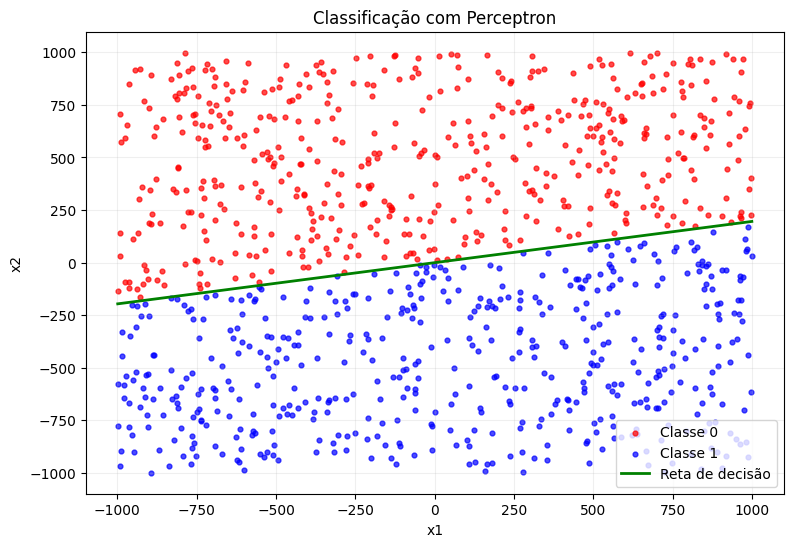

In [81]:

plt.figure(figsize=(9, 6))

plt.scatter(
    X[y == 0, 0], X[y == 0, 1],
    color="red", s=12, alpha=0.7, label="Classe 0"
)

plt.scatter(
    X[y == 1, 0], X[y == 1, 1],
    color="blue", s=12, alpha=0.7, label="Classe 1"
)

x_reta = np.linspace(X[:, 0].min(), X[:, 0].max(), 200)
y_reta = -(pesos[0] + pesos[1] * x_reta) / pesos[2]

plt.plot(x_reta, y_reta, color="green",
         linewidth=2, label="Reta de decisão")

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Classificação com Perceptron")
plt.legend()
plt.grid(alpha=0.2)
plt.show()


## Parte 2

In [82]:
dados2 = np.load("data320262.txt")

print("Dimensão original:", dados2.shape)

Dimensão original: (1000, 1, 3)


In [83]:
dados2 = dados2.reshape(-1, 3)

X2 = dados2[:, :2]
y2 = dados2[:, 2].astype(int)

print("Entradas:", X2.shape)
print("Rótulos:", y2.shape)
print("Classes:", np.unique(y2, return_counts=True))

Entradas: (1000, 2)
Rótulos: (1000,)
Classes: (array([0, 1]), array([346, 654]))


In [ ]:
n_repeticoes = 10
resultados = {}

for eta in [0.4, 0.1, 0.01]:
    for intervalo in [(-100, 100), (-0.5, 0.5)]:
        ajustes_exec = np.zeros(n_repeticoes, dtype=int)
        epocas_exec = np.zeros(n_repeticoes, dtype=int)

        for i in range(n_repeticoes):
            _, epocas_exec[i], ajustes_exec[i] = treinar_perceptron(
                X2, y2, eta=eta, intervalo=intervalo, seed=i, verbose=False
            )

        resultados[(eta, intervalo)] = (ajustes_exec, epocas_exec)

        print(f"Aprendizado: {eta}, Intervalo: {intervalo}")
        print(f"Total de ajustes: {ajustes_exec}")
        print(f"Total de épocas: {epocas_exec}")

Aprendizado: 0.4, Intervalo: (-100, 100)
Total de ajustes: [515900 464398 630730 261983 404298 511006 405539 204436 635997 350955]
Total de épocas: [5182 4455 7024 2088 3665 5115 3677 1532 7126 3023]
Aprendizado: 0.4, Intervalo: (-0.5, 0.5)
Total de ajustes: [334130 335182 260685 111769 507457 409344 388133 210506 336321 261392]
Total de épocas: [2825 2843 2074  747 5066 3728 3464 1585 2854 2082]
Aprendizado: 0.1, Intervalo: (-100, 100)
Total de ajustes: [138309 312052 217158 405689 329349 310916 257378 510965 260138 221273]
Total de épocas: [ 959 2596 1645 3667 2788 2592 2044 5117 2069 1695]
Aprendizado: 0.1, Intervalo: (-0.5, 0.5)
Total de ajustes: [312247 230343 217310 335639 213126 210313 333211 333435 218424 266370]
Total de épocas: [2607 1779 1652 2848 1612 1580 2817 2824 1659 2133]


In [ ]:
from prettytable import PrettyTable

tabela = PrettyTable()
tabela.field_names = ["Taxa de Aprendizado", "Intervalo de Pesos", "Qtde Ajustes", "Min Épocas", "Max Épocas"]

for (eta, intervalo), (ajustes_exec, epocas_exec) in resultados.items():
    tabela.add_row([
        f"η = {eta}",
        f"({intervalo[0]}, +{intervalo[1]})",
        f"{ajustes_exec.mean():.2f} ± {ajustes_exec.std(ddof=1):.2f}",
        epocas_exec.min(),
        epocas_exec.max(),
    ])

print(tabela)

In [ ]:
rotulos = [f"η={eta}\nI={intervalo}" for eta, intervalo in resultados]
ajustes_todos = [ajustes_exec for ajustes_exec, _ in resultados.values()]
epocas_todos = [epocas_exec for _, epocas_exec in resultados.values()]
posicoes = np.arange(1, len(rotulos) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.boxplot(ajustes_todos, showmeans=True)
ax1.set_xticks(posicoes, rotulos)
ax1.set_title("Quantidade de ajustes no vetor de pesos")
ax1.set_ylabel("Ajustes")
ax1.grid(alpha=0.2)

ax2.boxplot(epocas_todos, showmeans=True)
ax2.set_xticks(posicoes, rotulos)
ax2.set_title("Épocas até a convergência")
ax2.set_ylabel("Épocas")
ax2.grid(alpha=0.2)

fig.suptitle("Perceptron - 10 repetições por configuração (triângulo = média)")
plt.tight_layout()
plt.show()

### Análise dos resultados

Todas as 60 execuções convergiram, então o problema é linearmente separável. Mesmo assim, cada execução precisou de milhares de ajustes e de milhares de épocas. Portanto, não é possível identificar uma melhor ou pior, elas são equivalentes.

- A variação de cada configuração é muito grande, com cada desvio padrão dos ajustes chegando a cerca de 1/3 da média. Entre a execução mais rápida e a mais lenta de uma mesma configuração, o número de épocas varia de 2 a 5 vezes.
- Os bloxplots se sobrepôem, isto pois, a diferença entre as médias é da mesma ordem do desvio padrão. Com apenas 10 repetições, essas diferenças podem ser explicadas pelo sorteio dos pesos iniciais. Para afirmar com rigor que uma configuração é melhor, seria necessário um teste estatístico.

**Por que as configurações se comportam de forma parecida?**

1. **η só muda a escala dos pesos.** A função degrau depende apenas do sinal de $u$. Dividindo os pesos por η, a regra de ajuste vira $\mathbf{w}' \leftarrow \mathbf{w}' + e\,\mathbf{x}$, sem η. Ou seja, η não muda as previsões nem a reta encontrada. O que importa é apenas a razão $\mathbf{w}(0)/\eta$.
2. **A escala dos dados domina o treinamento.** $x_1$ e $x_2$ vão de −1000 a +1000, mas a entrada do bias vale 1. A cada ajuste, $w_1$ e $w_2$ mudam até ±1000·η, enquanto o bias muda só ±η. Por isso são necessários muitos ajustes até o bias atingir o valor que a reta exige. No final, os pesos são muito maiores que os iniciais, e o intervalo de inicialização, seja (−0.5, +0.5) ou (−100, +100), pesa pouco. Normalizar as entradas reduziria bastante o número de épocas.